# 09 — LSTM Tuning

Stage 10. Trains the LSTM (`src/dl_models.py`) and tunes a small grid on the 2013
validation year: history length (lookback), hidden size and number of layers. The
target and eval hours are those of Phase 1, so the numbers sit next to the XGBoost
tables. The frozen 2014 test comes later (notebook 10).

In [1]:
import sys, time, json
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, validate
from src import windows as W
from src.dl_models import LSTMForecaster
from src.evaluate import metrics
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
print('device check: running the grid on', LSTMForecaster().__class__.__name__)

device check: running the grid on LSTMForecaster


## 1. Tuning protocol

Each configuration is trained once on 2010–2012 and scored on the 2013 validation
eval set — the same hours used for every model. 2013 never leaks into training, so
the comparison is fair; a single held-out year (rather than Phase 1's four quarterly
folds) keeps the deep-learning search affordable. The best configuration is then
frozen for the 2014 test.

The LSTM learns the change `pm(t+1) - pm(t)` (the "delta" formulation), with dropout,
weight decay, gradient clipping and early stopping. Fixed grid otherwise:
`dropout=0.1`, `lr=1e-3`, `weight_decay=1e-4`, up to 40 epochs.

In [2]:
LOOKBACKS = [24, 48, 72]
HIDDENS = [32, 64]
LAYERS = [1, 2]

rows = []
for L in LOOKBACKS:
    X, y, split, mask, stats = W.build_sequence_dataset(df, lookback=L)
    pm_t = df['pm25'].ffill().reindex(mask.index).to_numpy('float32')
    sp, mk = split.to_numpy(), mask.to_numpy()
    tr = (sp == 'train') & ~np.isnan(y) & ~np.isnan(pm_t)      # observed target and pm(t)
    ve = (sp == 'val') & mk                                    # common 2013 eval set
    for h in HIDDENS:
        for nl in LAYERS:
            t0 = time.time()
            model = LSTMForecaster(hidden=h, layers=nl, dropout=0.1, epochs=40, seed=0)
            model.fit(X[tr], y[tr], pm_t[tr])
            pred = model.predict(X[ve], pm_t[ve])
            m = metrics(y[ve], pred)
            rows.append({'lookback': L, 'hidden': h, 'layers': nl,
                         'MAE': m['MAE'], 'RMSE': m['RMSE'], 'R2': m['R2'],
                         'fit_s': round(time.time() - t0, 1)})
            print(f"lookback={L:3d} hidden={h:3d} layers={nl}  MAE={m['MAE']:.3f}  RMSE={m['RMSE']:.3f}  ({rows[-1]['fit_s']}s)")

search = pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
(ROOT / 'results' / 'metrics').mkdir(parents=True, exist_ok=True)
search.to_csv(ROOT / 'results' / 'metrics' / 'lstm_search.csv', index=False)
search.round(3)

lookback= 24 hidden= 32 layers=1  MAE=12.789  RMSE=23.404  (17.7s)


lookback= 24 hidden= 32 layers=2  MAE=12.706  RMSE=23.235  (11.1s)


lookback= 24 hidden= 64 layers=1  MAE=12.594  RMSE=23.047  (13.5s)


lookback= 24 hidden= 64 layers=2  MAE=12.471  RMSE=22.849  (17.2s)


lookback= 48 hidden= 32 layers=1  MAE=12.853  RMSE=23.306  (21.6s)


lookback= 48 hidden= 32 layers=2  MAE=12.541  RMSE=23.059  (57.6s)


... (3 outputs left out)

lookback= 72 hidden= 32 layers=2  MAE=12.719  RMSE=23.202  (40.0s)


lookback= 72 hidden= 64 layers=1  MAE=12.515  RMSE=22.863  (38.2s)


lookback= 72 hidden= 64 layers=2  MAE=12.519  RMSE=22.941  (53.5s)


,lookback,hidden,layers,MAE,RMSE,R2,fit_s
0,24,64,2,12.471,22.849,0.946,17.2
1,72,64,1,12.515,22.863,0.946,38.2
2,72,64,2,12.519,22.941,0.945,53.5
3,48,32,2,12.541,23.059,0.945,57.6
4,24,64,1,12.594,23.047,0.945,13.5
5,24,32,2,12.706,23.235,0.944,11.1
6,72,32,2,12.719,23.202,0.944,40.0
7,48,64,2,12.744,23.178,0.944,51.9
8,48,64,1,12.768,23.248,0.944,18.1
9,24,32,1,12.789,23.404,0.943,17.7


## 2. Selected configuration

Lowest validation MAE wins. The choice is saved to
`results/metrics/lstm_selected_config.json` and reused by the test notebook.

In [3]:
best = search.iloc[0]
selected = {'lookback': int(best['lookback']), 'hidden': int(best['hidden']),
            'layers': int(best['layers']), 'dropout': 0.1, 'lr': 1e-3,
            'weight_decay': 1e-4, 'epochs': 40, 'formulation': 'delta', 'seed': 0,
            'val_MAE': float(best['MAE']), 'val_RMSE': float(best['RMSE']), 'val_R2': float(best['R2'])}
with open(ROOT / 'results' / 'metrics' / 'lstm_selected_config.json', 'w') as f:
    json.dump(selected, f, indent=2)
selected

{'lookback': 24,
 'hidden': 64,
 'layers': 2,
 'dropout': 0.1,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'epochs': 40,
 'formulation': 'delta',
 'seed': 0,
 'val_MAE': 12.470882402434745,
 'val_RMSE': 22.849217443827797,
 'val_R2': 0.9457990623346963}

## 3. Validation comparison

The selected LSTM against the Phase 1 models on the identical 2013 eval set.
Persistence and XGBoost come from the saved Phase 1 validation predictions.

In [4]:
xgb = pd.read_csv(ROOT / 'results' / 'predictions' / 'xgb_val_folds.csv')
comp = pd.DataFrame([
    {'model': 'persistence', **metrics(xgb['y_true'], xgb['persistence'])},
    {'model': 'XGBoost (change)', **metrics(xgb['y_true'], xgb['xgboost'])},
    {'model': f"LSTM (lookback {selected['lookback']}, hidden {selected['hidden']}, {selected['layers']}L)",
     'n': int(xgb.shape[0]), 'MAE': best['MAE'], 'RMSE': best['RMSE'], 'R2': best['R2']},
]).set_index('model')
comp[['n', 'MAE', 'RMSE', 'R2']].round(3)

,n,MAE,RMSE,R2
model,,,,
persistence,8563,13.184,24.870,0.936
XGBoost (change),8563,12.258,22.526,0.947
"LSTM (lookback 24, hidden 64, 2L)",8563,12.471,22.849,0.946


## 4. Effect of the grid

Validation MAE by history length, one line per (hidden, layers) setting.

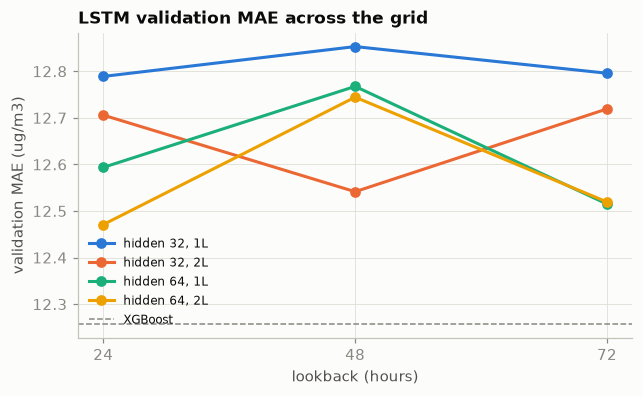

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, ((h, nl), g) in enumerate(search.sort_values('lookback').groupby(['hidden', 'layers'])):
    ax.plot(g['lookback'], g['MAE'], marker='o', color=ps.SERIES[i % len(ps.SERIES)],
            label=f'hidden {h}, {nl}L')
ax.axhline(metrics(xgb['y_true'], xgb['xgboost'])['MAE'], color=ps.MUTED, ls='--', lw=1, label='XGBoost')
ax.set_xlabel('lookback (hours)'); ax.set_ylabel('validation MAE (ug/m3)')
ax.set_title('LSTM validation MAE across the grid'); ax.set_xticks(search['lookback'].unique())
ax.legend(fontsize=8)
ps.save(fig, 'dl_02_lstm_search')
plt.show()